# Financial Processes: Lesson 3
## Pricing European options in Binomial Tree Model

# Agenda:

* European options
    * Market
    * Call, Put
* Tree method
    * Concept
    * Example
* Formula for price and delta
* Implementation
* Barrier options
* Coding

# European options

## The market

Two assets:
* Money market (risk free asset, bond): pays a fixed, deterministic interest

* Risky asset (stock): $S_t \sim F_t$, i.e. its present value is known, future is unknown

* Short position is allowed

* No bid-ask spread

## European option

Two parties:
* Option holder (buyer)

* Option writer (seller)

Parameters of the contract:
* Maturity, $T$

* Strike price, $K$

Def (European call/put option): The owner has the right, but not the obligation to buy/sell $1$ share of stock from/to the option writer at $T$ for $K$ (dollars).

Payoff of european call: $ \;\;\; max\lbrace S_T-K, 0\rbrace $

Payoff of european put: $ \;\;\; max\lbrace K - S_T, 0\rbrace $

# The Tree method

## Basic concept of binomial tree model
* Discrete steps, price goes up or down randomly
* Risk-free alternative is government bond

$$ d < 1 + r < u $$

<img src="./img/tree-notation.png" style="margin-left:auto; margin-right:auto; margin-top: 50px; width: 1200px;" />

More than one step is possible

Spot tree: $S_{t,i}$ is the $i^{th}$ value of the time $t$ level of the spot simulation tree. $t = 0, \dots, N,\ i = 0, \dots, t$.

<img src="./img/2-step.png" style="margin-left:auto; margin-right:auto; margin-top: 50px; width: 600px;" />

## Example: pricing European option with one-step tree

<img src="./img/1-step-example.png" style="margin-left:auto; margin-right:auto; margin-top: 150px; width: 1800px;" />

### Arbitrage free price of option

$\textbf{time step}$| $\textbf{draw}$ | $\textbf{bond} \hspace{10px}$ | $\textbf{stock}$ | $\textbf{call option}$ |
--------------:|----:|----:|----:|----:|
$0$|$\emptyset$|$-100$|$-20$|$V_0$
$1$|$U$|$103$|$22$|$1$
$1$|$D$|$103$|$18$|$0$

Q: What is the basic idea?

Can we replicate the cashflows of the option using bonds and stock?

$ S_1(U)-S_1(D) = 4 (V_1(U) - V_1(D)) $

We need to hold $ \Delta_0 = 1/4 $ number of stocks to replicate (Delta-hedging rule)

time step| draw | $\text{bond} \hspace{10px}$  |  $1/4$ stock  | $\text{option} \hspace{10px}$ |
---:|---:|---:|---:|---:|
$0$|$\emptyset$|$\approx 4.37$|$-5$|$V_0\approx 0.63$
$1$|$U$|$-4.5$|$5.5$|$1$
$1$|$D$|$-4.5$|$4.5$|$0$

Q: Where did we use $p$ and $q$?

Q: What if option had another price on the market?

Q: How would you generalize to multi-step?

# Price formula

## One step

* Example table gives an equation system for $V_0$ and $\Delta_0$: amount of stocks to hold for replication

$ V_0 = \frac{1}{1+r}(\tilde{p}\ V_1(U) + \tilde{q}\ V_1(D)) $ and

$ \Delta_0 = \frac{V_1(U) - V_1(D)}{S_1(U) - S_1(D)} $

where

$ \tilde{p} =  \frac{1+r-d}{u-d}$,  $ \tilde{q} = 1 - \tilde{p} $

Q: Where do the formulas depend on the strike $K$?

$\{ \tilde{p}, \tilde{q}\}$ is called the Risk-neutral measure

$ V_0 = \frac{1}{1+r}\tilde{E}(V_1) $

Q: Why do we call it "Risk-neutral measure"?

## Multi-step

  $ V_n = \frac{1}{1+r}\tilde{E}(V_{n+1} \mid \mathcal{F}_n) $
  
  $ \Delta_n = \frac{V_{n+1}(\dots U) - V_{n+1}(\dots D)}{S_{n+1}(\dots U) - S_{n+1}(\dots D)}$
  
  $\text{ for } \ n = N-1,\dots,0$

Therefore:

$ V_0 = \frac{1}{(1+r)^N}\tilde{E}(V_N) $

# Implementation

Two trees:

* Spot tree: $S_{t,i}$ is the $i^{th}$ value of the time $t$ level of the spot simulation tree. $t = 0, \dots, N,\ i = 0, \dots, t$.

<img src="./img/2-step.png" style="margin-left:auto; margin-right:auto; margin-top: 50px; width: 600px;" />

## Evolution of spot tree: code snippet

<img src="./img/spot_tree_code_spaghetti.jpg" style="margin-left:auto; margin-right:auto; margin-top: 150px; width: 1800px;" />

Two trees:
* Spot tree: $S_{t,i}$ is the $i^{th}$ value of the time $t$ level of the spot simulation tree. $t = 0, \dots, N,\ i = 0, \dots, t$.
* **Price tree:** same dimensions, $V_{t,i} = \tilde{E}(V_N \mid S_t = S_{t,i}) $

* Backward solution for price tree (based on multi-step formula)

## Evolution of price tree: code snippets

Leaves:
<img src="./img/price_tree_leaves_European_spaghetti.jpg" style="margin-left:auto; margin-right:1000px; margin-top: 10px; width: 1350px;" />

Backward steps:
<img src="./img/price_tree_code_European_spaghetti.jpg" style="margin-left:auto; margin-right:550px; margin-top: 10px; width: 1800px;" />

## Barrier options

Up and out call: call with a knock-out feature

Barrier: $B>K$

$$V_T = (S_T - K)^+ \mathbb{1}\{S_t < B \ \ \ \forall 0 \leq t \leq T\}$$

Continous barrier: barrier condition is checked on a time interval (as opposed to either terminal condition or discrete barrier)

Q: Main difference from modeling perspective?

# Time to play a bit with the code...

# Summary and discussion

* Market, European Call/Put

* Spot and Price tree

* Replication, hedging

* Formula for price and delta
    * $ V_0 = \tilde{E}(V_N) $, $ V_n = \tilde{E}(V_N \mid \mathcal{F}_n) $
    * To replicate we need to achieve:

      $ \Delta_n(S_{n+1}(\dots U) - S_{n+1}(\dots D)) = V_{n+1}(\dots U) - V_{n+1}(\dots D) $

* In jupyter nb we have seen:
    * Delta is dynamic
    * Balancing the tree
    * Barrier

# Assignment
## Implement calibrator for Tree

* Background: In the Black--Scholes model volatility is a key parameter that determines option price. In a Balanced Binomial Tree (i.e. risk-neutral up step probability $= 0.5$ risk-neutral down step probability $= 0.5$) the same role is played by step size: higher step is like higher volatility, it results in higher option prices. Also, there is a 1-1 correspondence between step size and price if all other parameters are fixed.
* Task: Write a calibrate method which, for a given number of steps parameter, computes the up step size for which a Balanced Binomial Tree model returns the specified price for a given European call. (In practice option prices can be observed in the market, so it makes sense to assume it is given). Demonstrate the calibrate method for various input parameters (same contract with a few different number of steps (dont forget to scale the discount factor to keep interest rates flat); calibrate one step tree for various contracts (different expiries and strike levels, flat interest rate)). Make simple plots to illustrate results.
* Hint: To do it you will need to use a root solver, I recommend using scipy.optimize.minimize.

In [11]:
class Tree:
    def __init__(self, S0, K, T, r, steps):
        self.S0 = S0
        self.K = K
        self.T = T
        self.r = r
        self.steps = steps

    def price(self, u):
        growth = np.exp(self.r * self.T / self.steps)
        d = 2 * growth - u  # Makes the risk-neutral up probability 0.5.

        # Call payoffs at the final level of the tree.
        values = []
        for up_moves in range(self.steps + 1):
            stock = self.S0 * u**up_moves * d**(self.steps - up_moves)
            values.append(max(stock - self.K, 0))

        # Work backwards to today's option price.
        for level in range(self.steps - 1, -1, -1):
            values = [
                (values[i] + values[i + 1]) / (2 * growth)
                for i in range(level + 1)
            ]

        return values[0]
    
    def calibrate(self, market_price):
        growth = np.exp(self.r * self.T / self.steps)
        smallest_u = growth
        largest_u = 2 * growth - 1e-10  # Keep the down factor positive.

        if abs(market_price - self.price(smallest_u)) < 1e-10:
            return smallest_u
        if abs(market_price - self.price(largest_u)) < 1e-10:
            return largest_u

        return brentq(
            lambda u: self.price(u) - market_price,
            smallest_u,
            largest_u
        )


In [12]:
def bsm_call(S0, K, T, r, sigma):
    """Make example target prices instead of using real market quotes."""
    d1 = (np.log(S0 / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)



Same contract, different numbers of steps:
steps    target       tree price   up factor    down factor
    1    10.450584    10.450584    1.219728     0.882814
    2    10.450584    10.450584    1.175628     0.875002
    4    10.450584    10.450584    1.113772     0.911385
    8    10.450584    10.450584    1.076632     0.935907
   16    10.450584    10.450584    1.052727     0.953532
   32    10.450584    10.450584    1.036700     0.966428

One-step tree, different calls:
expiry   strike    target       tree price   up factor
   0.5       90    13.498517    13.498517    1.176805
   0.5      100     6.888729     6.888729    1.141262
   0.5      110     2.906471     2.906471    1.159601
   1.0       90    16.699448    16.699448    1.251113
   1.0      100    10.450584    10.450584    1.219728
   1.0      110     6.040088     6.040088    1.226995
   2.0       90    22.033380    22.033380    1.387013
   2.0      100    16.126780    16.126780    1.356457
   2.0      110    11.455456    11.

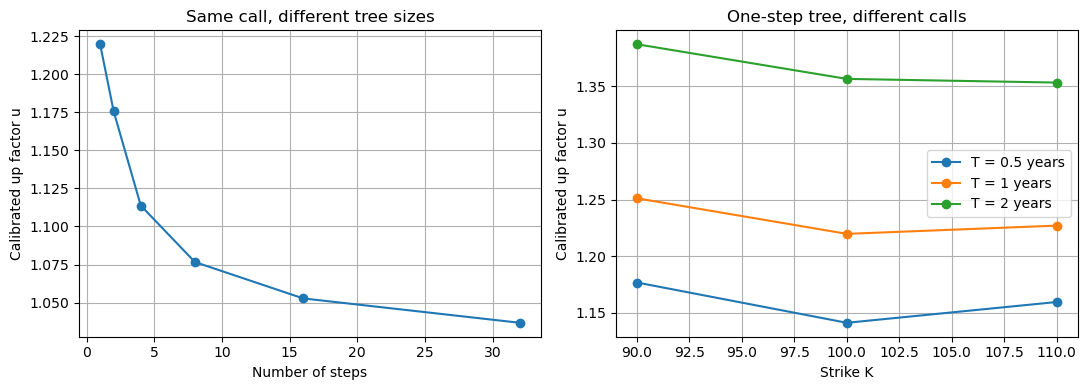

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm


S0 = 100
r = 0.05       # Same annual interest rate in both experiments.
sigma = 0.20   # Used only to make example target prices.

# Experiment 1: same call, different numbers of steps.
K, T = 100, 1
target = bsm_call(S0, K, T, r, sigma)
step_counts = [1, 2, 4, 8, 16, 32]
up_factors = []

print("Same contract, different numbers of steps:")
print("steps    target       tree price   up factor    down factor")

for steps in step_counts:
    tree = Tree(S0, K, T, r, steps)
    u = tree.calibrate(target)

    growth = np.exp(r * T / steps)
    d = 2 * growth - u
    up_factors.append(u)

    print(
        f"{steps:5d}  {target:11.6f}  {tree.price(u):11.6f}"
        f"  {u:10.6f}  {d:11.6f}"
    )
    assert abs(tree.price(u) - target) < 1e-7

# Experiment 2: one-step trees with different strikes and expiries.
strikes = [90, 100, 110]
expiries = [0.5, 1, 2]

print("\nOne-step tree, different calls:")
print("expiry   strike    target       tree price   up factor")

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(step_counts, up_factors, "o-")
plt.xlabel("Number of steps")
plt.ylabel("Calibrated up factor u")
plt.title("Same call, different tree sizes")
plt.grid(True)

plt.subplot(1, 2, 2)

for T in expiries:
    factors = []

    for K in strikes:
        target = bsm_call(S0, K, T, r, sigma)
        tree = Tree(S0, K, T, r, 1)
        u = tree.calibrate(target)
        factors.append(u)

        print(
            f"{T:6.1f}  {K:7d}  {target:11.6f}"
            f"  {tree.price(u):11.6f}  {u:10.6f}"
        )
        assert abs(tree.price(u) - target) < 1e-7

    plt.plot(strikes, factors, "o-", label=f"T = {T} years")

plt.xlabel("Strike K")
plt.ylabel("Calibrated up factor u")
plt.title("One-step tree, different calls")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Literature
* Steven Shreve: Stochastic Calculus and Finance I.

# Thanks

<img src="./img/money_tree.jpg" style="margin-left:auto; margin-right:auto; margin-top: 100px; width: 700px;" />